# Mini Project Machine Learning (Bab 14)
## Prediksi Churn Pelanggan Telekomunikasi: Komparasi Model, Tuning, dan Deployment

**Dataset:** Telco Customer Churn (IBM sample data, Kaggle `blastchar/telco-customer-churn`) · **Alur:** CRISP-DM (Business Understanding → Data Understanding → Data Preparation → Modeling → Evaluation → Deployment)

**Cara pakai di Google Colab:** jalankan sel dari atas ke bawah. Saat diminta, unggah file `WA_Fn-UseC_-Telco-Customer-Churn.csv`. Seluruh proses (termasuk tuning) memakan waktu beberapa menit. Di akhir notebook, folder `paket_deploy.zip` berisi semua file yang dibutuhkan untuk deploy ke Streamlit.

**Keluaran notebook:** `model_terbaik.pkl`, `model_meta.json`, `feature_importance.csv`, `fitur_telco.py`, `app.py`, `requirements.txt`, dan folder `gambar/` (grafik untuk laporan).

## 1. Business Understanding

**Masalah bisnis.** Perusahaan telekomunikasi kehilangan pelanggan (*churn*). Mempertahankan pelanggan yang sudah ada umumnya lebih murah daripada mencari pelanggan baru, tetapi program retensi (diskon, upgrade kontrak) sendiri berbiaya. Karena itu program harus ditujukan pada pelanggan yang paling mungkin pergi.

**Tujuan proyek.** Membangun model klasifikasi biner (`Churn` = Yes/No) yang menghasilkan *skor risiko* tiap pelanggan sehingga tim pemasaran dapat memprioritaskan penawaran retensi, lalu membungkusnya dalam aplikasi web sederhana.

**Rumusan masalah.** (1) Faktor apa yang paling berkaitan dengan churn? (2) Algoritma mana yang paling baik dan layak dipakai? (3) Berapa nilai finansial program retensi berbasis model dibanding tanpa model?

**Metrik keberhasilan.** Akurasi **tidak** dipakai sebagai metrik utama karena hanya ≈26,5% pelanggan yang churn (model yang selalu menebak "tidak churn" sudah ≈73,5% akurat). Metrik yang dipakai:
- **PR-AUC** (*average precision*): metrik utama, tidak bergantung pada ambang keputusan dan peka terhadap kelas minoritas.
- **Recall, Precision, F1** pada kelas churn, pada ambang keputusan terpilih.
- **Estimasi keuntungan bersih** program retensi berdasarkan asumsi biaya di bawah.
- **Interpretabilitas** dan kecepatan sebagai pertimbangan praktis (sesuai Bab 14.2 dan 14.9).

**Asumsi biaya (ilustratif, dapat diganti dengan data perusahaan).**

| Parameter | Simbol | Nilai | Arti |
|---|---|---|---|
| Nilai pelanggan yang berhasil dipertahankan | V | US$300 | margin yang diperoleh jika pelanggan tidak jadi pergi |
| Biaya penawaran retensi | C | US$30 | diskon/kupon per pelanggan yang dihubungi |
| Peluang penawaran berhasil | p | 50% | proporsi pelanggan berisiko yang benar-benar bertahan |

Manfaat bersih menghubungi satu pelanggan = p·V − C jika ia memang akan churn (US$120), dan −C jika tidak (−US$30). Titik impas: menghubungi pelanggan menguntungkan bila peluang churn-nya ≥ C/(p·V) = **20%**.

In [1]:
import sys, subprocess, os, json, time, warnings, shutil, importlib.metadata as im
try:
    import imblearn
except ImportError:                      # di Colab biasanya sudah tersedia
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "imbalanced-learn"])
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)

SEED = 42
NILAI_PELANGGAN, BIAYA_TAWARAN, RASIO_BERHASIL = 300, 30, 0.5     # asumsi bisnis (V, C, p)
os.makedirs("gambar", exist_ok=True)

def simpan(nama):
    plt.savefig(f"gambar/{nama}.png", dpi=150, bbox_inches="tight")
print("Siap. Titik impas menghubungi pelanggan = peluang churn >=", BIAYA_TAWARAN / (RASIO_BERHASIL * NILAI_PELANGGAN))

Siap. Titik impas menghubungi pelanggan = peluang churn >= 0.2


## 2. Data Understanding

In [2]:
NAMA_FILE = "WA_Fn-UseC_-Telco-Customer-Churn.csv"
if not os.path.exists(NAMA_FILE):
    try:
        from google.colab import files
        print("Unggah file", NAMA_FILE)
        files.upload()
    except ImportError:
        raise FileNotFoundError(f"Letakkan {NAMA_FILE} di folder yang sama dengan notebook ini.")

df = pd.read_csv(NAMA_FILE)
print("Ukuran data:", df.shape)
df.head()

Ukuran data: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [3]:
# Kualitas data
print("Tipe data:"); print(df.dtypes.to_string())
print("\nMissing value (NaN) per kolom:", int(df.isna().sum().sum()))

# TotalCharges bertipe teks -> ada nilai kosong tersembunyi berupa spasi
tc = pd.to_numeric(df["TotalCharges"], errors="coerce")
print("\nTotalCharges yang tidak bisa dikonversi ke angka:", int(tc.isna().sum()))
print("Nilai tenure pada baris tersebut:", df.loc[tc.isna(), "tenure"].unique())
print("customerID unik:", df["customerID"].is_unique)
print("Baris duplikat (selain customerID):", int(df.drop(columns="customerID").duplicated().sum()))
print("\nDistribusi target:"); print(df["Churn"].value_counts().to_frame("jumlah").assign(proporsi=lambda d: (d["jumlah"] / len(df)).round(3)))

Tipe data:
customerID              str
gender                  str
SeniorCitizen         int64
Partner                 str
Dependents              str
tenure                int64
PhoneService            str
MultipleLines           str
InternetService         str
OnlineSecurity          str
OnlineBackup            str
DeviceProtection        str
TechSupport             str
StreamingTV             str
StreamingMovies         str
Contract                str
PaperlessBilling        str
PaymentMethod           str
MonthlyCharges      float64
TotalCharges            str
Churn                   str

Missing value (NaN) per kolom: 0

TotalCharges yang tidak bisa dikonversi ke angka: 11
Nilai tenure pada baris tersebut: [0]
customerID unik: True
Baris duplikat (selain customerID): 22

Distribusi target:
       jumlah  proporsi
Churn                  
No       5174     0.735
Yes      1869     0.265


**Temuan kualitas data:** 
- Tidak ada `NaN`, tetapi `TotalCharges` bertipe teks dan menyembunyikan **11 nilai kosong** (berupa spasi). Seluruhnya milik pelanggan dengan `tenure` = 0, yaitu pelanggan baru yang belum pernah ditagih. Jadi ini bukan data hilang acak, melainkan konsekuensi logis.
- `customerID` unik untuk semua baris. Ada **22 baris yang identik pada seluruh kolom lainnya** (0,3% data); dibiarkan karena merupakan pelanggan berbeda dengan profil layanan sama (kombinasi kategori yang terbatas membuat kemiripan ini wajar).
- Target **tidak seimbang**: 1.869 pelanggan churn (26,5%) dan 5.174 bertahan (73,5%), sehingga akurasi bukan metrik yang tepat.

### 2.1 Pembersihan minimal dan pemisahan data (sebelum EDA)
`TotalCharges` kosong hanya pada pelanggan baru (`tenure` = 0) yang belum pernah ditagih, sehingga nilai yang logis adalah **0** (aturan domain, bukan estimasi dari data). Data kemudian dipisah **80% latih / 20% uji secara stratified** sebelum eksplorasi, agar seluruh keputusan analisis hanya bersandar pada data latih. Data uji baru dibuka pada tahap evaluasi akhir.

In [4]:
from sklearn.model_selection import train_test_split, StratifiedKFold

df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce").fillna(0)
y = (df["Churn"] == "Yes").astype(int)                   # 1 = churn
X = df.drop(columns=["customerID", "Churn"])

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)
print("Data latih:", X_train.shape, "| Data uji:", X_test.shape)
print("Proporsi churn latih/uji:", round(y_train.mean(), 4), "/", round(y_test.mean(), 4))
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)     # fold yang SAMA untuk semua model

Data latih: (5634, 19) | Data uji: (1409, 19)
Proporsi churn latih/uji: 0.2654 / 0.2654


### 2.2 Exploratory Data Analysis (data latih)

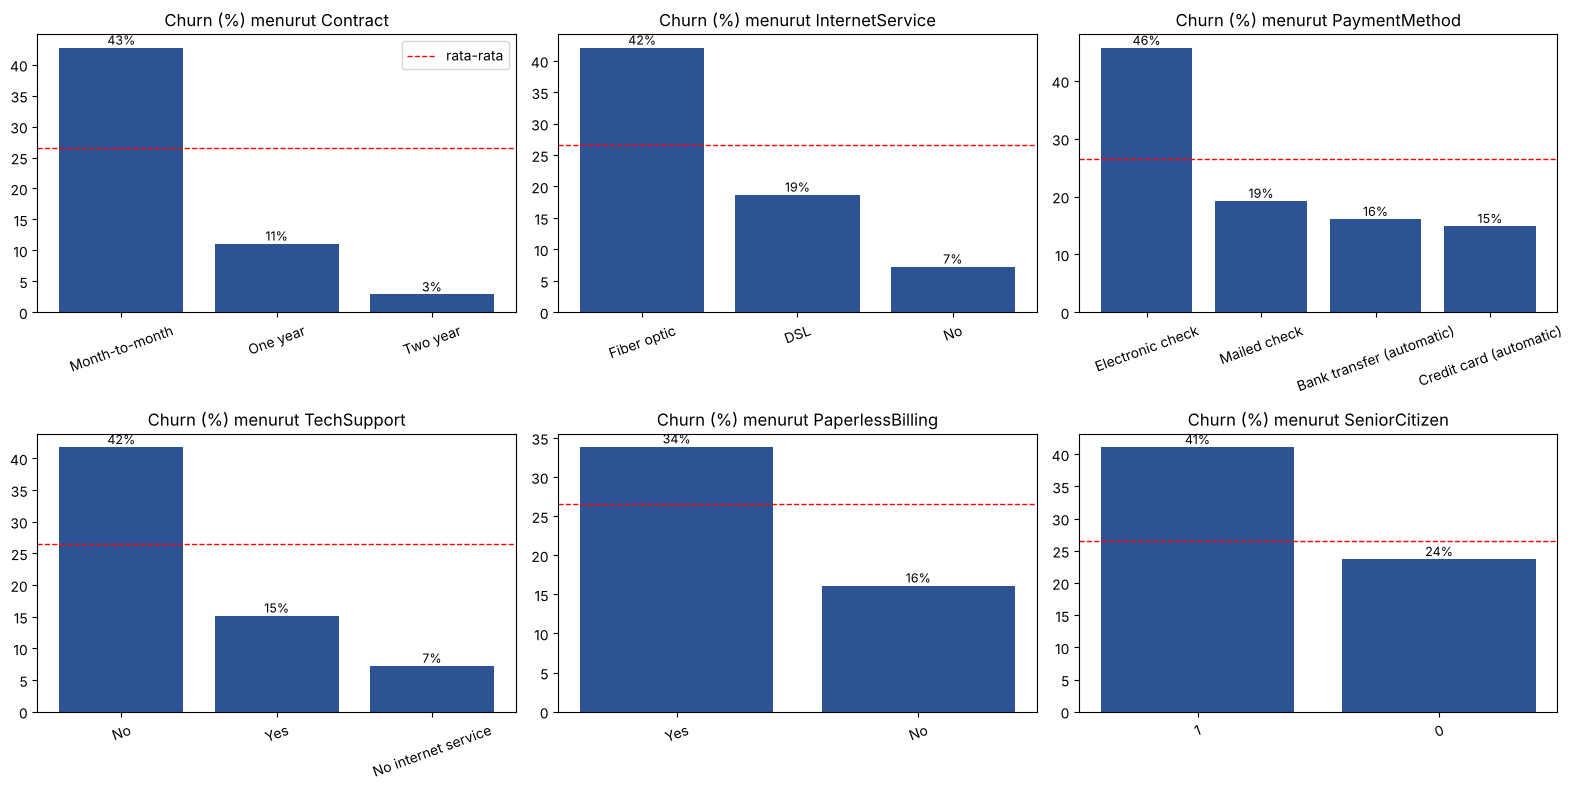

In [5]:
eda = X_train.copy(); eda["Churn"] = y_train.values

# (a) Tingkat churn per kategori pada fitur-fitur utama
fitur_plot = ["Contract", "InternetService", "PaymentMethod", "TechSupport", "PaperlessBilling", "SeniorCitizen"]
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for ax, f in zip(axes.ravel(), fitur_plot):
    tingkat = eda.groupby(f)["Churn"].mean().sort_values(ascending=False) * 100
    ax.bar(tingkat.index.astype(str), tingkat.values, color="#2E5395")
    ax.axhline(eda["Churn"].mean() * 100, color="red", ls="--", lw=1, label="rata-rata")
    ax.set_title(f"Churn (%) menurut {f}"); ax.tick_params(axis="x", rotation=20)
    for i, v in enumerate(tingkat.values): ax.text(i, v + 0.5, f"{v:.0f}%", ha="center", fontsize=9)
axes[0, 0].legend()
plt.tight_layout(); simpan("eda_churn_per_kategori"); plt.show()

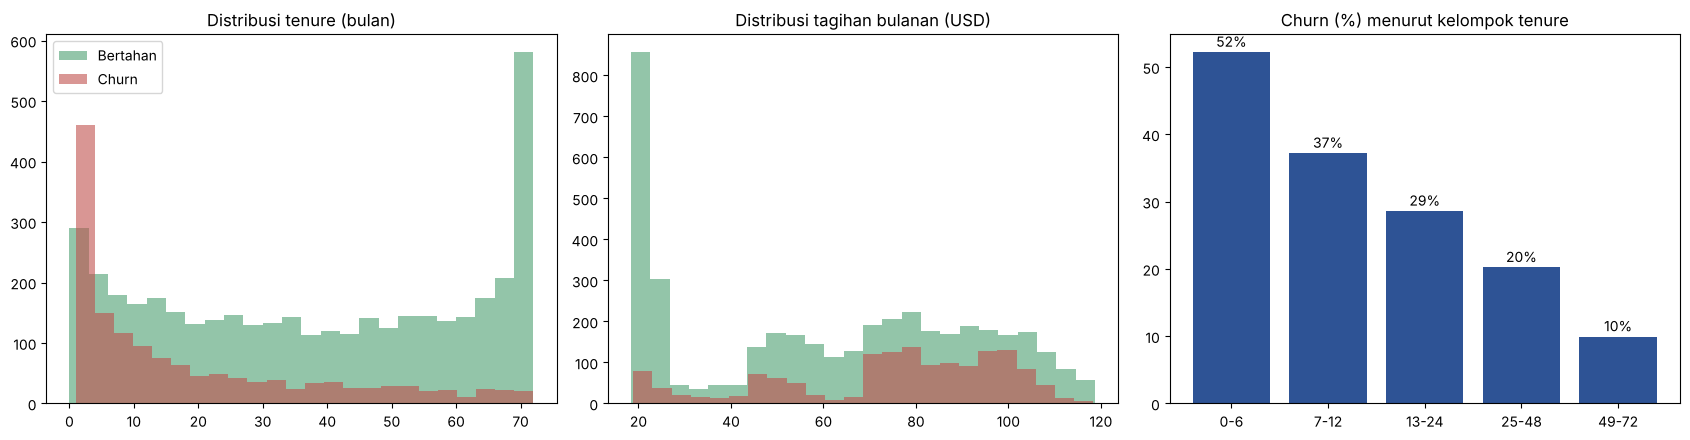

      tenure        MonthlyCharges       
        mean median           mean median
Churn                                    
0       37.6   38.0           61.3   64.4
1       18.4   10.0           74.9   80.0


In [6]:
# (b) Tenure dan tagihan bulanan: perbandingan pelanggan churn vs tidak
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
for nilai, label, warna in [(0, "Bertahan", "#4C9F70"), (1, "Churn", "#C0504D")]:
    axes[0].hist(eda.loc[eda["Churn"] == nilai, "tenure"], bins=24, alpha=0.6, label=label, color=warna)
    axes[1].hist(eda.loc[eda["Churn"] == nilai, "MonthlyCharges"], bins=24, alpha=0.6, label=label, color=warna)
axes[0].set_title("Distribusi tenure (bulan)"); axes[1].set_title("Distribusi tagihan bulanan (USD)")
axes[0].legend()

eda["kelompok_tenure"] = pd.cut(eda["tenure"], [-1, 6, 12, 24, 48, 72], labels=["0-6", "7-12", "13-24", "25-48", "49-72"])
t = eda.groupby("kelompok_tenure", observed=True)["Churn"].mean() * 100
axes[2].bar(t.index.astype(str), t.values, color="#2E5395"); axes[2].set_title("Churn (%) menurut kelompok tenure")
for i, v in enumerate(t.values): axes[2].text(i, v + 0.8, f"{v:.0f}%", ha="center")
plt.tight_layout(); simpan("eda_tenure_tagihan"); plt.show()
print(eda.groupby("Churn")[["tenure", "MonthlyCharges"]].agg(["mean", "median"]).round(1))

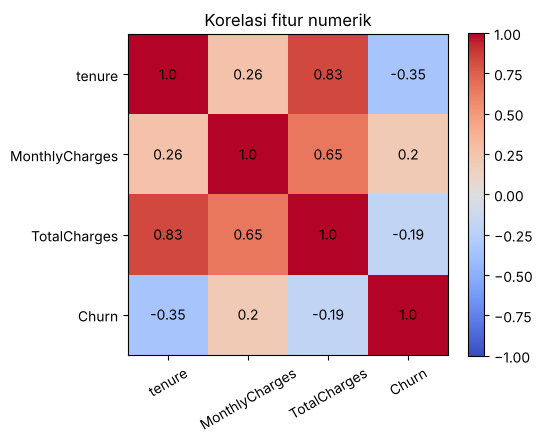

Korelasi TotalCharges dengan (tenure x MonthlyCharges): 1.0


In [7]:
# (c) Korelasi fitur numerik dan redundansi TotalCharges
num = eda[["tenure", "MonthlyCharges", "TotalCharges", "Churn"]]
korelasi = num.corr().round(2)
fig, ax = plt.subplots(figsize=(5.5, 4.5))
im_ = ax.imshow(korelasi.values, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(4)); ax.set_xticklabels(korelasi.columns, rotation=30); ax.set_yticks(range(4)); ax.set_yticklabels(korelasi.columns)
for i in range(4):
    for j in range(4): ax.text(j, i, korelasi.values[i, j], ha="center", va="center")
plt.colorbar(im_); ax.set_title("Korelasi fitur numerik"); plt.tight_layout(); simpan("eda_korelasi"); plt.show()
est_total = eda["tenure"] * eda["MonthlyCharges"]
print("Korelasi TotalCharges dengan (tenure x MonthlyCharges):", round(np.corrcoef(eda["TotalCharges"], est_total)[0, 1], 3))

**Insight EDA:**


1. **Jenis kontrak adalah pembeda terkuat.** Churn pada kontrak bulanan **42,7%**, kontrak 1 tahun 11,1%, dan kontrak 2 tahun hanya **2,9%**. Kontrak bulanan mencakup 3.102 dari 5.634 pelanggan latih (55%).
2. **Pelanggan baru paling rentan.** Churn mencapai **52,2%** pada pelanggan 0-6 bulan dan turun bertahap menjadi 9,9% pada 49-72 bulan. Median tenure pelanggan churn hanya 10 bulan (vs 38 bulan pada yang bertahan). `tenure` berkorelasi -0,35 dengan churn, paling kuat di antara fitur numerik.
3. **Fiber optic dan *electronic check* berisiko tinggi.** Churn internet fiber 42,1% (DSL 18,7%, tanpa internet 7,2%), dan electronic check 45,7% (metode lain 15-19%). Kombinasi kontrak bulanan + fiber + electronic check memiliki churn **60,9%** (1.052 pelanggan). *Catatan:* ini korelasi, bukan sebab. Pelanggan churn juga membayar lebih mahal (rata-rata US$74,9 vs US$61,3 per bulan), sehingga harga bisa menjadi penjelas, bukan teknologi fiber itu sendiri.
4. **Layanan pendukung berasosiasi dengan churn rendah.** Tanpa TechSupport churn 41,8% vs 15,2% dengan TechSupport; tanpa OnlineSecurity 41,9% vs 14,4%.
5. Tagihan tanpa kertas (33,8% vs 16,0%) dan pelanggan lansia (41,1% vs 23,7%) juga memiliki churn lebih tinggi.
6. `TotalCharges` hampir identik dengan `tenure × MonthlyCharges` (korelasi 0,9996), sehingga redundan.

## 3. Data Preparation
Seluruh preprocessing dibungkus dalam satu `Pipeline` (kode ada di modul `fitur_telco.py`) agar persis sama saat pelatihan, validasi silang, dan deployment. Sel di bawah menulis modul itu ke disk; **modul inilah yang nanti diimpor oleh `app.py`**.

Keputusan preprocessing:
- `customerID` dibuang (identitas, tidak informatif).
- `TotalCharges` **tidak dipakai** karena redundan dengan `tenure × MonthlyCharges` (lihat korelasi di EDA) dan sulit diisi pengguna di aplikasi. Keputusan ini diuji pada ablasi di bawah.
- **Feature engineering:** `jumlah_layanan_tambahan` (banyaknya layanan tambahan yang dilanggan, 0-6).
- `tenure`, `MonthlyCharges`, dan `jumlah_layanan_tambahan` di-*scaling* (`StandardScaler`); kolom kategorikal di-*one-hot encoding* (`handle_unknown="ignore"`); `SeniorCitizen` sudah 0/1.
- Tidak ada penghapusan outlier: nilai numerik berada pada rentang wajar (tenure 0-72, tagihan US$18-119).

In [8]:
%%writefile fitur_telco.py
"""
fitur_telco.py
Modul pendukung Mini Project Prediksi Churn Pelanggan Telco.
Dipakai oleh NOTEBOOK (saat melatih) dan oleh APLIKASI STREAMLIT (saat memprediksi),
sehingga pipeline preprocessing identik di kedua tempat (prinsip Bab 4 dan Bab 14.4).
"""
import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler
from sklearn.svm import SVC

LAYANAN_TAMBAHAN = ["OnlineSecurity", "OnlineBackup", "DeviceProtection",
                    "TechSupport", "StreamingTV", "StreamingMovies"]

# 18 kolom mentah yang diminta dari pengguna (TotalCharges dan customerID sengaja tidak dipakai)
FITUR_MENTAH = ["gender", "SeniorCitizen", "Partner", "Dependents", "tenure",
                "PhoneService", "MultipleLines", "InternetService", *LAYANAN_TAMBAHAN,
                "Contract", "PaperlessBilling", "PaymentMethod", "MonthlyCharges"]

FITUR_NUMERIK = ["tenure", "MonthlyCharges", "jumlah_layanan_tambahan"]   # di-scaling
FITUR_BINER = ["SeniorCitizen"]                                            # sudah 0/1
FITUR_KATEGORIKAL = [c for c in FITUR_MENTAH
                     if c not in ("SeniorCitizen", "tenure", "MonthlyCharges")]


def tambah_fitur(X):
    """Feature engineering: jumlah layanan tambahan yang dilanggan (0-6)."""
    X = X.copy()
    X["jumlah_layanan_tambahan"] = (X[LAYANAN_TAMBAHAN] == "Yes").sum(axis=1)
    return X


def bangun_preprocessor():
    return ColumnTransformer([
        ("num", StandardScaler(), FITUR_NUMERIK),
        ("bin", "passthrough", FITUR_BINER),
        ("cat", OneHotEncoder(handle_unknown="ignore", drop="if_binary"), FITUR_KATEGORIKAL),
    ])


def bangun_pipeline(estimator):
    """Pipeline lengkap: rekayasa fitur -> preprocessing -> model."""
    return Pipeline([
        ("fitur", FunctionTransformer(tambah_fitur, validate=False)),
        ("prep", bangun_preprocessor()),
        ("model", estimator),
    ])


# Dipakai aplikasi untuk melatih ulang bila versi scikit-learn di server berbeda
REGISTRY = {
    "LogisticRegression": LogisticRegression,
    "RandomForestClassifier": RandomForestClassifier,
    "HistGradientBoostingClassifier": HistGradientBoostingClassifier,
    "SVC": SVC,
}
KONFIG_TETAP = {
    "LogisticRegression": dict(max_iter=2000),
    "RandomForestClassifier": dict(random_state=42),
    "HistGradientBoostingClassifier": dict(random_state=42),
    "SVC": dict(kernel="rbf"),
}


def buat_estimator(nama, params):
    return REGISTRY[nama](**{**KONFIG_TETAP.get(nama, {}), **params})

Overwriting fitur_telco.py


In [9]:
import importlib, fitur_telco as ft
importlib.reload(ft)

Xtr, Xte = X_train[ft.FITUR_MENTAH], X_test[ft.FITUR_MENTAH]
ytr, yte = y_train.values, y_test.values

contoh = ft.bangun_pipeline(__import__("sklearn.linear_model", fromlist=["LogisticRegression"]).LogisticRegression())
contoh.named_steps["fitur"].fit(Xtr); Xt = contoh.named_steps["prep"].fit_transform(contoh.named_steps["fitur"].transform(Xtr))
print("Fitur mentah:", Xtr.shape[1], "-> setelah rekayasa & encoding:", Xt.shape[1])
print("Contoh nama fitur:", list(contoh.named_steps["prep"].get_feature_names_out()[:8]))

Fitur mentah: 18 -> setelah rekayasa & encoding: 40
Contoh nama fitur: ['num__tenure', 'num__MonthlyCharges', 'num__jumlah_layanan_tambahan', 'bin__SeniorCitizen', 'cat__gender_Male', 'cat__Partner_Yes', 'cat__Dependents_Yes', 'cat__PhoneService_Yes']


### 3.1 Ablasi keputusan fitur (Regresi Logistik dan Gradient Boosting default, 5-fold CV pada data latih)

In [10]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_validate

from sklearn.ensemble import HistGradientBoostingClassifier

def pipa_fitur(estimator, num_cols):
    prep = ColumnTransformer([("num", StandardScaler(), num_cols), ("bin", "passthrough", ft.FITUR_BINER),
                              ("cat", OneHotEncoder(handle_unknown="ignore", drop="if_binary"), ft.FITUR_KATEGORIKAL)])
    return Pipeline([("fitur", FunctionTransformer(ft.tambah_fitur, validate=False)), ("prep", prep), ("model", estimator)])

varian = {
    "Final: tanpa TotalCharges + fitur rekayasa": ft.FITUR_NUMERIK,
    "Menambahkan TotalCharges": ft.FITUR_NUMERIK + ["TotalCharges"],
    "Tanpa fitur rekayasa (jumlah_layanan_tambahan)": ["tenure", "MonthlyCharges"],
}
model_ablasi = {"Logistic Regression": lambda: LogisticRegression(max_iter=2000),
                "Gradient Boosting (default)": lambda: HistGradientBoostingClassifier(random_state=SEED)}
baris = []
for nm, buat in model_ablasi.items():
    for nama, kolom in varian.items():
        hs = cross_validate(pipa_fitur(buat(), kolom), X_train, ytr, cv=skf, scoring=["average_precision", "roc_auc"])
        baris.append({"Model": nm, "Varian fitur": nama, "PR-AUC CV": hs["test_average_precision"].mean(),
                      "Std": hs["test_average_precision"].std(), "ROC-AUC CV": hs["test_roc_auc"].mean()})
tabel_ablasi = pd.DataFrame(baris); tabel_ablasi.round(4)

,Model,Varian fitur,PR-AUC CV,Std,ROC-AUC CV
0,Logistic Regression,Final: tanpa TotalCharges + fitur rekayasa,0.6596,0.0188,0.8449
1,Logistic Regression,Menambahkan TotalCharges,0.6616,0.0195,0.8462
2,Logistic Regression,Tanpa fitur rekayasa (jumlah_layanan_tambahan),0.6597,0.0188,0.8449
3,Gradient Boosting (default),Final: tanpa TotalCharges + fitur rekayasa,0.6437,0.0211,0.8359
4,Gradient Boosting (default),Menambahkan TotalCharges,0.6499,0.0228,0.8396
5,Gradient Boosting (default),Tanpa fitur rekayasa (jumlah_layanan_tambahan),0.6486,0.0212,0.8355


**Hasil ablasi fitur:** 
- **`TotalCharges` tidak diperlukan.** Menambahkannya hanya menaikkan PR-AUC CV sebesar 0,002 (Regresi Logistik) dan 0,006 (Gradient Boosting), jauh di bawah simpangan baku antar-fold (≈0,02), sehingga tidak bermakna secara statistik. Tanpanya, aplikasi cukup meminta `tenure` dan `MonthlyCharges`.
- **Fitur rekayasa `jumlah_layanan_tambahan` tidak memberi peningkatan terukur.** Pada Regresi Logistik hasilnya identik (0,6596 vs 0,6597); wajar, karena fitur ini kombinasi linear dari kolom one-hot layanan tambahan dan tidak menambah informasi bagi model linear. Pada Gradient Boosting default skornya malah sedikit lebih rendah (0,6437 vs 0,6486), tetapi masih dalam rentang noise. Fitur ini **dipertahankan** karena tidak merugikan secara terukur dan mudah dijelaskan secara bisnis. Ini temuan yang perlu dilaporkan apa adanya: fitur tersebut bukan sumber peningkatan kinerja, dan pada sistem produksi dapat dihapus demi kesederhanaan.

### 3.2 Strategi penanganan imbalance (Regresi Logistik, out-of-fold pada data latih)
Dibandingkan lima strategi: (1) tanpa penanganan, ambang 0,5; (2) `class_weight="balanced"`; (3) SMOTE (hanya diterapkan pada data latih di tiap fold melalui pipeline `imblearn`); (4) tanpa penanganan + **ambang keputusan disetel berdasarkan keuntungan bisnis**; (5) `class_weight` + ambang disetel. Semua dievaluasi pada prediksi *out-of-fold* yang sama (5-fold).

In [11]:
from sklearn.model_selection import cross_val_predict
from sklearn.base import clone
from sklearn.metrics import (average_precision_score, roc_auc_score, f1_score, recall_score, precision_score,
                             precision_recall_curve, confusion_matrix)
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE

def profit_bersih(y_true, skor, ambang):
    """Keuntungan bersih menghubungi semua pelanggan dengan skor >= ambang."""
    y_true = np.asarray(y_true); pilih = np.asarray(skor) >= ambang
    return float(np.sum(np.where(y_true[pilih] == 1, RASIO_BERHASIL * NILAI_PELANGGAN, 0.0) - BIAYA_TAWARAN))

def cari_ambang(y_true, skor):
    kandidat = np.unique(np.quantile(skor, np.linspace(0, 0.995, 400)))
    laba = [profit_bersih(y_true, skor, t) for t in kandidat]
    i = int(np.argmax(laba)); return float(kandidat[i]), float(laba[i])

def pipa_imb(class_weight=None, smote=False):
    langkah = [("fitur", FunctionTransformer(ft.tambah_fitur, validate=False)), ("prep", ft.bangun_preprocessor())]
    if smote: langkah.append(("smote", SMOTE(random_state=SEED)))
    langkah.append(("model", LogisticRegression(max_iter=2000, class_weight=class_weight)))
    return (ImbPipeline if smote else Pipeline)(langkah)

oof = {"A": cross_val_predict(pipa_imb(), Xtr, ytr, cv=skf, method="predict_proba")[:, 1],
       "B": cross_val_predict(pipa_imb(class_weight="balanced"), Xtr, ytr, cv=skf, method="predict_proba")[:, 1],
       "C": cross_val_predict(pipa_imb(smote=True), Xtr, ytr, cv=skf, method="predict_proba")[:, 1]}
t_a, _ = cari_ambang(ytr, oof["A"]); t_b, _ = cari_ambang(ytr, oof["B"])
strategi = [("(1) Tanpa penanganan, ambang 0,5", oof["A"], 0.5), ("(2) class_weight=balanced, ambang 0,5", oof["B"], 0.5),
            ("(3) SMOTE, ambang 0,5", oof["C"], 0.5), ("(4) Tanpa penanganan + ambang bisnis", oof["A"], t_a),
            ("(5) class_weight + ambang bisnis", oof["B"], t_b)]
baris = []
for nama, skor, t in strategi:
    p = (skor >= t).astype(int)
    baris.append({"Strategi": nama, "Ambang": round(t, 3), "F1": f1_score(ytr, p), "Recall": recall_score(ytr, p),
                  "Precision": precision_score(ytr, p), "PR-AUC": average_precision_score(ytr, skor),
                  "Profit per 1.000 pelanggan (US$)": profit_bersih(ytr, skor, t) / len(ytr) * 1000})
tabel_imbalance = pd.DataFrame(baris); tabel_imbalance.round(3)

,Strategi,Ambang,F1,Recall,Precision,PR-AUC,Profit per 1.000 pelanggan (US$)
0,"(1) Tanpa penanganan, ambang 0,5",0.500,0.590,0.539,0.652,0.657,14872.204
1,"(2) class_weight=balanced, ambang 0,5",0.500,0.628,0.793,0.519,0.655,19414.271
2,"(3) SMOTE, ambang 0,5",0.500,0.631,0.779,0.531,0.654,19307.774
3,(4) Tanpa penanganan + ambang bisnis,0.163,0.599,0.897,0.450,0.657,19840.256
4,(5) class_weight + ambang bisnis,0.338,0.596,0.906,0.444,0.655,19813.632


**Hasil perbandingan strategi imbalance:** 
- **Dengan ambang baku 0,5, model tanpa penanganan gagal menangkap banyak churner:** recall hanya 0,539 (46% churner terlewat) dengan keuntungan US$14.872 per 1.000 pelanggan.
- **`class_weight` dan SMOTE** menaikkan recall menjadi ≈0,78-0,79 dan F1 menjadi ≈0,63, dengan keuntungan ≈US$19.300-19.400 per 1.000 pelanggan. Hasil keduanya hampir identik, sehingga SMOTE tidak memberi keunggulan dibanding `class_weight` yang jauh lebih sederhana.
- **Menyetel ambang keputusan** pada model tanpa penanganan menghasilkan keuntungan tertinggi (US$19.840 per 1.000), dan menambahkan `class_weight` di atasnya tidak menambah apa pun (US$19.814). Ambang optimal 0,163 mendekati titik impas teoretis 0,20.
- **Mengapa F1 tertinggi pada strategi (2) dan (3), tetapi keuntungan tertinggi pada (4)?** F1 memberi bobot setara pada precision dan recall, sedangkan secara bisnis melewatkan satu churner (kehilangan peluang US$120) empat kali lebih mahal daripada menghubungi pelanggan yang tidak akan pergi (US$30). Ambang berbasis biaya karena itu mengutamakan recall (0,897).
- **Keputusan:** ketidakseimbangan ditangani dengan **menyetel ambang berdasarkan biaya**, tanpa resampling dan tanpa `class_weight`. Cara ini paling sederhana, menghasilkan keuntungan tertinggi, dan menjaga skor model tetap berupa probabilitas yang terkalibrasi (dipakai langsung di aplikasi).

## 4. Modeling
Empat algoritma dari keluarga berbeda dibandingkan dengan **protokol yang sama**: data latih yang sama, `StratifiedKFold(5)` yang sama, dan tuning `RandomizedSearchCV` dengan metrik yang sama. Metrik penyetelan (`refit`) adalah **PR-AUC**; F1 dan ROC-AUC dicatat sebagai pelengkap.

| Model | Alasan dipilih |
|---|---|
| Logistic Regression | Baseline linear yang mudah dijelaskan |
| Random Forest | Ensemble bagging, menangkap interaksi non-linear |
| Gradient Boosting (`HistGradientBoostingClassifier`) | Ensemble boosting, umumnya kuat pada data tabular; versi histogram agar cepat |
| SVM (kernel RBF) | Model berbasis margin non-linear |

In [12]:
from sklearn.model_selection import RandomizedSearchCV
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.svm import SVC

ruang_model = {
    "Logistic Regression": (LogisticRegression(max_iter=2000),
        {"model__C": [0.01, 0.03, 0.1, 0.3, 1, 3, 10, 30]}, 8),
    "Random Forest": (RandomForestClassifier(random_state=SEED),
        {"model__n_estimators": [200, 300, 500], "model__max_depth": [4, 6, 8, 12, None],
         "model__min_samples_leaf": [1, 3, 5, 10, 20], "model__max_features": ["sqrt", 0.3, 0.5]}, 10),
    "Gradient Boosting": (HistGradientBoostingClassifier(random_state=SEED),
        {"model__learning_rate": [0.03, 0.05, 0.1], "model__max_depth": [2, 3, 4, None],
         "model__max_iter": [100, 200, 300], "model__min_samples_leaf": [20, 40, 80],
         "model__l2_regularization": [0, 1, 5]}, 10),
    "SVM (RBF)": (SVC(kernel="rbf"),
        {"model__C": [0.3, 1, 3, 10], "model__gamma": ["scale", 0.01, 0.03, 0.1]}, 6),
}
SCORING = {"average_precision": "average_precision", "roc_auc": "roc_auc", "f1": "f1"}

hasil, baris = {}, []
for nama, (est, grid, n_iter) in ruang_model.items():
    t0 = time.time()
    cari = RandomizedSearchCV(ft.bangun_pipeline(est), grid, n_iter=n_iter, cv=skf, scoring=SCORING,
                              refit="average_precision", random_state=SEED, n_jobs=-1)
    cari.fit(Xtr, ytr)
    i = cari.best_index_; waktu = time.time() - t0
    hasil[nama] = {"best": cari.best_estimator_, "params": {k.replace("model__", ""): v for k, v in cari.best_params_.items()}}
    baris.append({"Model": nama, "PR-AUC CV": cari.cv_results_["mean_test_average_precision"][i],
                  "Std": cari.cv_results_["std_test_average_precision"][i],
                  "ROC-AUC CV": cari.cv_results_["mean_test_roc_auc"][i], "F1 CV (ambang 0,5)": cari.cv_results_["mean_test_f1"][i],
                  "Waktu tuning (dtk)": waktu, "Hyperparameter terbaik": hasil[nama]["params"]})
    print(f"{nama:20s} selesai dalam {waktu:5.1f} dtk | PR-AUC CV = {baris[-1]['PR-AUC CV']:.4f}")
tabel_tuning = pd.DataFrame(baris); tabel_tuning.round(4)

Logistic Regression  selesai dalam   2.7 dtk | PR-AUC CV = 0.6598


Random Forest        selesai dalam  69.4 dtk | PR-AUC CV = 0.6642


Gradient Boosting    selesai dalam  15.9 dtk | PR-AUC CV = 0.6703


SVM (RBF)            selesai dalam  23.5 dtk | PR-AUC CV = 0.6550


,Model,PR-AUC CV,Std,ROC-AUC CV,"F1 CV (ambang 0,5)",Waktu tuning (dtk),Hyperparameter terbaik
0,Logistic Regression,0.6598,0.0188,0.8449,0.5862,2.7180,{'C': 0.1}
1,Random Forest,0.6642,0.0187,0.8470,0.5801,69.3961,"{'n_estimators': 300, 'min_samples_leaf': 20, ..."
2,Gradient Boosting,0.6703,0.0211,0.8494,0.5900,15.8887,"{'min_samples_leaf': 80, 'max_iter': 200, 'max..."
3,SVM (RBF),0.6550,0.0156,0.8387,0.5768,23.4550,"{'gamma': 0.01, 'C': 1}"


**Hasil tuning:** 
Keempat model hampir sama kuat: PR-AUC CV berkisar **0,655-0,670** (Gradient Boosting 0,670, Random Forest 0,664, Logistic Regression 0,660, SVM 0,655). Selisih terbesarnya (0,015) lebih kecil daripada simpangan baku antar-fold (≈0,016-0,021), sehingga perbedaan antar-algoritma belum dapat dibedakan secara statistik. Biaya tuningnya sangat berbeda: Logistic Regression 3,4 detik, Gradient Boosting 15 detik, SVM 25 detik, dan Random Forest 73 detik. Pada Logistic Regression, regularisasi cukup kuat (`C=0,1`) yang terpilih. Pola yang sebagian besar linear pada data ini menjelaskan mengapa model non-linear tidak jauh lebih baik.

## 5. Evaluation

**Protokol yang adil.** Setiap model dinilai pada *ambang keputusan terbaiknya masing-masing*, yaitu ambang yang memaksimalkan keuntungan bisnis pada prediksi *out-of-fold* data latih (tanpa menyentuh data uji). Data uji dipakai **sekali** di akhir sebagai konfirmasi.

**Pemilihan model.** Mengikuti contoh 14.9 modul, dipakai **skor gabungan = 0,7 × F1 (CV, pada ambang terpilih) + 0,3 × (interpretabilitas/5)**. Skala interpretabilitas (1-5) adalah penilaian subjektif: Logistic Regression 5, Random Forest 3, Gradient Boosting 2, SVM 1. Bobot ini asumsi yang dapat didiskusikan; PR-AUC tetap diperiksa agar model terpilih tidak jauh lebih lemah dari yang terbaik.

In [13]:
INTERPRETABILITAS = {"Logistic Regression": 5, "Random Forest": 3, "Gradient Boosting": 2, "SVM (RBF)": 1}

def skor_model(model, X):
    return model.predict_proba(X)[:, 1] if hasattr(model, "predict_proba") else model.decision_function(X)

baris, oof_skor, skor_uji, ambang = [], {}, {}, {}
for nama, h in hasil.items():
    best = h["best"]
    metode = "predict_proba" if hasattr(best, "predict_proba") else "decision_function"
    o = cross_val_predict(clone(best), Xtr, ytr, cv=skf, method=metode)
    o = o[:, 1] if metode == "predict_proba" else o
    t, _ = cari_ambang(ytr, o)
    p_cv = (o >= t).astype(int)

    s_te = skor_model(best, Xte); p_te = (s_te >= t).astype(int)
    t0 = time.time(); clone(best).fit(Xtr, ytr); waktu_latih = time.time() - t0
    t0 = time.time(); best.predict(Xte); waktu_pred = (time.time() - t0) / len(Xte) * 1000 * 1000   # ms per 1000 baris

    oof_skor[nama], skor_uji[nama], ambang[nama] = o, s_te, t
    baris.append({"Model": nama, "Ambang": t,
                  "PR-AUC CV": average_precision_score(ytr, o), "F1 CV": f1_score(ytr, p_cv), "Recall CV": recall_score(ytr, p_cv),
                  "PR-AUC Uji": average_precision_score(yte, s_te), "ROC-AUC Uji": roc_auc_score(yte, s_te),
                  "F1 Uji": f1_score(yte, p_te), "Recall Uji": recall_score(yte, p_te), "Precision Uji": precision_score(yte, p_te),
                  "Profit per 1.000 (Uji, US$)": profit_bersih(yte, s_te, t) / len(yte) * 1000,
                  "Waktu latih (dtk)": waktu_latih, "Prediksi (ms/1000 baris)": waktu_pred,
                  "Interpretabilitas (1-5)": INTERPRETABILITAS[nama]})

tabel_eval = pd.DataFrame(baris)
tabel_eval["Skor gabungan"] = 0.7 * tabel_eval["F1 CV"] + 0.3 * tabel_eval["Interpretabilitas (1-5)"] / 5
tabel_eval = tabel_eval.sort_values("Skor gabungan", ascending=False).reset_index(drop=True)
nama_terpilih = tabel_eval.loc[0, "Model"]
print("Model terpilih (skor gabungan tertinggi):", nama_terpilih)
tabel_eval.round(3).T

Model terpilih (skor gabungan tertinggi): Logistic Regression


,0,1,2,3
Model,Logistic Regression,Random Forest,Gradient Boosting,SVM (RBF)
Ambang,0.159,0.19,0.211,-1.051
PR-AUC CV,0.657,0.66,0.668,0.652
F1 CV,0.597,0.611,0.623,0.61
Recall CV,0.902,0.88,0.862,0.868
PR-AUC Uji,0.63,0.653,0.662,0.628
ROC-AUC Uji,0.839,0.845,0.845,0.834
F1 Uji,0.596,0.603,0.612,0.605
Recall Uji,0.904,0.856,0.84,0.88
Precision Uji,0.445,0.466,0.482,0.461


**Pembahasan perbandingan model:** 
| Model | PR-AUC uji | F1 uji | Recall uji | Precision uji | Keuntungan per 1.000 (US$) | Skor gabungan |
|---|---|---|---|---|---|---|
| **Logistic Regression** | 0,630 | 0,596 | 0,904 | 0,445 | 19.801 | **0,718** |
| Random Forest | 0,653 | 0,603 | 0,856 | 0,466 | 19.439 | 0,608 |
| Gradient Boosting | 0,662 | 0,612 | 0,840 | 0,482 | 19.546 | 0,556 |
| SVM (RBF) | 0,628 | 0,605 | 0,880 | 0,461 | 19.844 | 0,487 |

- **Kualitas pengurutan:** Gradient Boosting dan Random Forest memiliki PR-AUC uji tertinggi (0,662 dan 0,653 vs 0,630 pada Logistic Regression). Namun pada area operasi (recall 0,84-0,90) kurva Precision-Recall keempat model hampir berimpit, dan **keuntungan bisnis hampir sama**: US$19.439-19.844 per 1.000 pelanggan (selisih ≤ 2,1%).
- **Skor gabungan memilih Logistic Regression (0,718)**, karena paling mudah dijelaskan (interpretabilitas 5/5), tercepat dilatih (≈0,05 detik) dan jauh lebih cepat memprediksi daripada SVM (puluhan milidetik vs ≈170 ms per 1.000 baris; angka waktu bervariasi antar-eksekusi), serta menghasilkan skor terkalibrasi.
- **Seberapa kuat pilihan ini?** Pilihan tetap Logistic Regression selama bobot interpretabilitas lebih dari ≈4% (di bawah itu Gradient Boosting yang menang). Jadi kesimpulannya tidak bergantung pada bobot 30% yang saya pakai, yang memang penilaian subjektif.
- **Catatan jujur:** jika tujuan utamanya semata akurasi pengurutan, Gradient Boosting layak dipertimbangkan. Namun data uji hanya berisi 374 churner, sehingga PR-AUC memiliki ketidakpastian sekitar ±0,025 dan selisih 0,03 belum meyakinkan.

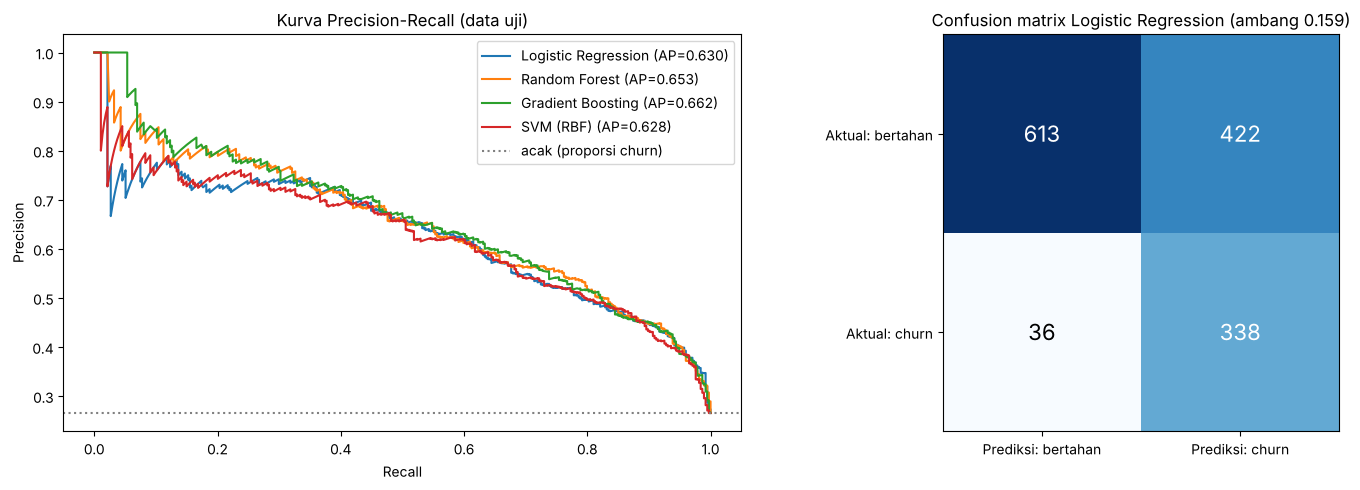

In [14]:
# Kurva Precision-Recall (data uji) dan confusion matrix pada ambang masing-masing model
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for nama in hasil:
    pr, rc, _ = precision_recall_curve(yte, skor_uji[nama])
    axes[0].plot(rc, pr, label=f"{nama} (AP={average_precision_score(yte, skor_uji[nama]):.3f})")
axes[0].axhline(yte.mean(), color="gray", ls=":", label="acak (proporsi churn)")
axes[0].set_xlabel("Recall"); axes[0].set_ylabel("Precision"); axes[0].set_title("Kurva Precision-Recall (data uji)"); axes[0].legend()

nama_cm = nama_terpilih
cm = confusion_matrix(yte, (skor_uji[nama_cm] >= ambang[nama_cm]).astype(int))
axes[1].imshow(cm, cmap="Blues")
for i in range(2):
    for j in range(2): axes[1].text(j, i, cm[i, j], ha="center", va="center", fontsize=16, color="white" if cm[i, j] > cm.max() / 2 else "black")
axes[1].set_xticks([0, 1]); axes[1].set_xticklabels(["Prediksi: bertahan", "Prediksi: churn"])
axes[1].set_yticks([0, 1]); axes[1].set_yticklabels(["Aktual: bertahan", "Aktual: churn"])
axes[1].set_title(f"Confusion matrix {nama_cm} (ambang {ambang[nama_cm]:.3f})")
plt.tight_layout(); simpan("evaluasi_pr_cm"); plt.show()

### 5.1 Dampak bisnis model terpilih (data uji)

In [15]:
model_final = hasil[nama_terpilih]["best"]
t_final = ambang[nama_terpilih]
s_final = skor_uji[nama_terpilih]
n_uji = len(yte)
dihubungi = s_final >= t_final

skenario = [
    ("Tidak ada program retensi", 0, 0, 0.0),
    ("Hubungi semua pelanggan", n_uji, int(yte.sum()), profit_bersih(yte, np.zeros(n_uji), 0)),
    (f"Hubungi berdasarkan model ({nama_terpilih})", int(dihubungi.sum()), int(yte[dihubungi].sum()), profit_bersih(yte, s_final, t_final)),
    ("Batas atas (hanya hubungi yang pasti churn)", int(yte.sum()), int(yte.sum()), int(yte.sum()) * (RASIO_BERHASIL * NILAI_PELANGGAN - BIAYA_TAWARAN)),
]
tabel_bisnis = pd.DataFrame(skenario, columns=["Skenario", "Pelanggan dihubungi", "Churner tertangkap", "Keuntungan bersih (US$)"])
tabel_bisnis["Per 1.000 pelanggan (US$)"] = tabel_bisnis["Keuntungan bersih (US$)"] / n_uji * 1000
tabel_bisnis["Recall churn"] = tabel_bisnis["Churner tertangkap"] / yte.sum()
print(f"Jumlah churner di data uji: {int(yte.sum())} dari {n_uji} pelanggan")
tabel_bisnis.round(2)

Jumlah churner di data uji: 374 dari 1409 pelanggan


,Skenario,Pelanggan dihubungi,Churner tertangkap,Keuntungan bersih (US$),Per 1.000 pelanggan (US$),Recall churn
0,Tidak ada program retensi,0,0,0.0,0.00,0.0
1,Hubungi semua pelanggan,1409,374,13830.0,9815.47,1.0
2,Hubungi berdasarkan model (Logistic Regression),760,338,27900.0,19801.28,0.9
3,Batas atas (hanya hubungi yang pasti churn),374,374,44880.0,31852.38,1.0


In [16]:
# Sensitivitas ambang terhadap asumsi biaya (pada prediksi out-of-fold data latih)
baris = []
for C in [15, 30, 60]:
    for p in [0.3, 0.5, 0.7]:
        impas = C / (p * NILAI_PELANGGAN)
        kand = np.unique(np.quantile(oof_skor[nama_terpilih], np.linspace(0, 0.995, 400)))
        laba = [np.sum(np.where(ytr[oof_skor[nama_terpilih] >= t] == 1, p * NILAI_PELANGGAN, 0) - C) for t in kand]
        t_opt = kand[int(np.argmax(laba))]
        baris.append({"Biaya tawaran C (US$)": C, "Peluang berhasil p": p, "Titik impas teoretis": round(impas, 2),
                      "Ambang optimal (OOF)": round(float(t_opt), 3),
                      "Pelanggan dihubungi (%)": round(float((oof_skor[nama_terpilih] >= t_opt).mean() * 100), 1)})
pd.DataFrame(baris)

,Biaya tawaran C (US$),Peluang berhasil p,Titik impas teoretis,Ambang optimal (OOF),Pelanggan dihubungi (%)
0,15,0.3,0.17,0.159,53.6
1,15,0.5,0.10,0.084,66.1
2,15,0.7,0.07,0.066,70.1
3,30,0.3,0.33,0.329,34.4
4,30,0.5,0.20,0.159,53.6
5,30,0.7,0.14,0.141,56.4
6,60,0.3,0.67,0.645,11.0
7,60,0.5,0.40,0.396,29.2
8,60,0.7,0.29,0.271,39.7


**Pembahasan dampak bisnis:** 
- **Model mengandalkan ≈54% pelanggan teratas.** Dengan ambang 0,159, model menghubungi 760 dari 1.409 pelanggan uji dan menangkap **338 dari 374 churner (recall 90%)**. Manfaat kotor US$50.700 (338 × p·V), dikurangi biaya penawaran US$22.800 (760 × C), menghasilkan **keuntungan bersih US$27.900**.
- **Dibanding strategi lain:** menghubungi semua pelanggan hanya menghasilkan US$13.830, sehingga program berbasis model **menggandakan keuntungan (+US$14.070, +102%)**. Hasil ini mencapai 62% dari batas atas teoretis US$44.880 (andaikan kita tahu pasti siapa yang akan churn).
- **Biaya false alarm:** 422 pelanggan yang sebenarnya bertahan ikut ditawari (≈US$12.660), tetapi ongkos itu jauh lebih kecil dari manfaat menyelamatkan churner. Karena itu ambang model sengaja rendah (recall tinggi, precision 0,445).
- **Sensitivitas:** ambang optimal bergerak mengikuti asumsi dan umumnya dekat dengan titik impas teoretis C/(p·V). Jika penawaran mahal dan jarang berhasil (C=60, p=0,3), hanya ≈11% pelanggan teratas yang layak dihubungi; jika murah dan sering berhasil (C=15, p=0,7), ≈70%.
- **Peringatan:** V, C, dan p adalah **asumsi ilustratif**. Angka rupiah/dolar di atas tidak boleh dilaporkan sebagai hasil riil; ganti dengan data perusahaan sebelum dipakai mengambil keputusan.

### 5.2 Interpretasi model: faktor apa yang mendorong churn?

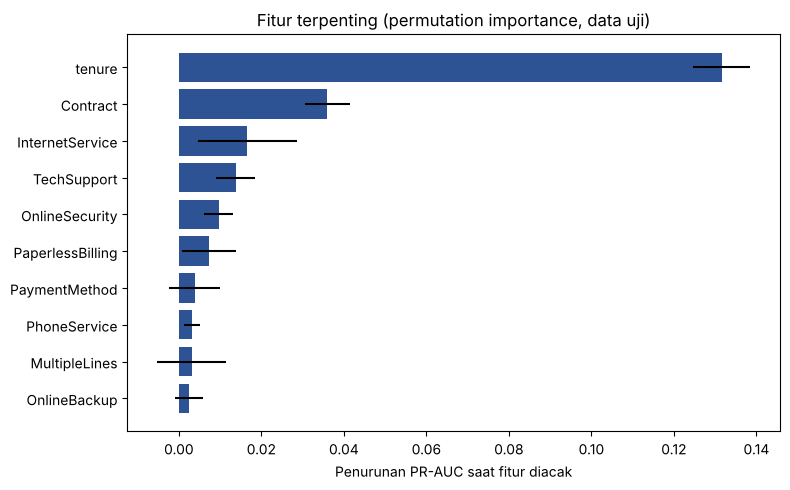

,fitur,penting,std
0,tenure,0.1316,0.0069
1,Contract,0.0360,0.0054
2,InternetService,0.0166,0.0120
3,TechSupport,0.0137,0.0048
4,OnlineSecurity,0.0096,0.0034
5,PaperlessBilling,0.0072,0.0065
6,PaymentMethod,0.0038,0.0062
7,PhoneService,0.0033,0.0019
8,MultipleLines,0.0031,0.0084
9,OnlineBackup,0.0024,0.0034


In [17]:
from sklearn.inspection import permutation_importance

pi = permutation_importance(model_final, Xte, yte, scoring="average_precision", n_repeats=10, random_state=SEED, n_jobs=1)
fi = (pd.DataFrame({"fitur": Xte.columns, "penting": pi.importances_mean, "std": pi.importances_std})
      .sort_values("penting", ascending=False).reset_index(drop=True))

plt.figure(figsize=(8, 5))
top = fi.head(10).iloc[::-1]
plt.barh(top["fitur"], top["penting"], xerr=top["std"], color="#2E5395")
plt.xlabel("Penurunan PR-AUC saat fitur diacak"); plt.title("Fitur terpenting (permutation importance, data uji)")
plt.tight_layout(); simpan("feature_importance"); plt.show()
fi.head(10).round(4)

In [18]:
# Koefisien model linear (jika model terpilih linear): rasio odds per 1 simpangan baku / per kategori
est_akhir = model_final.named_steps["model"]
if hasattr(est_akhir, "coef_"):
    nama_f = model_final.named_steps["prep"].get_feature_names_out()
    koef = pd.DataFrame({"fitur": [n.split("__", 1)[1] for n in nama_f], "koefisien": est_akhir.coef_[0]})
    koef["rasio_odds"] = np.exp(koef["koefisien"])
    koef = koef.sort_values("koefisien", ascending=False)
    print("Faktor yang MENAIKKAN risiko churn (rasio odds > 1):"); print(koef.head(8).round(3).to_string(index=False))
    print("\nFaktor yang MENURUNKAN risiko churn (rasio odds < 1):"); print(koef.tail(8).iloc[::-1].round(3).to_string(index=False))
else:
    print("Model terpilih bukan model linear; gunakan permutation importance di atas.")

Faktor yang MENAIKKAN risiko churn (rasio odds > 1):
                         fitur  koefisien  rasio_odds
       Contract_Month-to-month      0.626       1.871
   InternetService_Fiber optic      0.419       1.520
          PaperlessBilling_Yes      0.356       1.428
PaymentMethod_Electronic check      0.271       1.312
             OnlineSecurity_No      0.250       1.284
                TechSupport_No      0.225       1.253
                MonthlyCharges      0.155       1.168
               StreamingTV_Yes      0.154       1.166

Faktor yang MENURUNKAN risiko churn (rasio odds < 1):
                                fitur  koefisien  rasio_odds
                               tenure     -0.789       0.454
                    Contract_Two year     -0.572       0.565
                  InternetService_DSL     -0.338       0.713
                       Dependents_Yes     -0.223       0.800
                     MultipleLines_No     -0.220       0.803
                   OnlineSecurity_Yes   

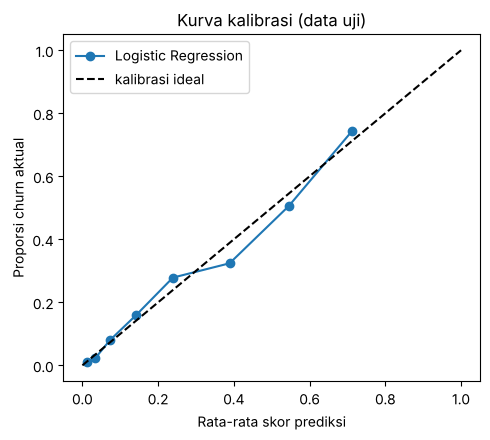

Rata-rata skor prediksi: 0.268 | proporsi churn aktual: 0.265


In [19]:
# Kalibrasi: apakah skor model dapat dibaca sebagai probabilitas? (penting karena aplikasi menampilkan persentase)
from sklearn.calibration import calibration_curve
if hasattr(model_final, "predict_proba"):
    frac, rata = calibration_curve(yte, s_final, n_bins=8, strategy="quantile")
    plt.figure(figsize=(5, 4.5)); plt.plot(rata, frac, "o-", label=nama_terpilih); plt.plot([0, 1], [0, 1], "k--", label="kalibrasi ideal")
    plt.xlabel("Rata-rata skor prediksi"); plt.ylabel("Proporsi churn aktual"); plt.title("Kurva kalibrasi (data uji)")
    plt.legend(); plt.tight_layout(); simpan("kalibrasi"); plt.show()
    print("Rata-rata skor prediksi:", round(float(s_final.mean()), 3), "| proporsi churn aktual:", round(float(yte.mean()), 3))

**Interpretasi faktor churn dan kalibrasi:** 
- **`tenure` mendominasi.** Mengacak `tenure` menurunkan PR-AUC sebesar 0,132, sekitar 3,7 kali pengaruh `Contract` (0,036), diikuti `InternetService` (0,017), `TechSupport` (0,014), dan `OnlineSecurity` (0,010). Fitur peringkat keenam ke bawah memiliki simpangan baku yang hampir sama besar dengan nilainya, sehingga kontribusinya tidak dapat dibedakan dari nol.
- **Rasio odds Regresi Logistik** (dibaca dengan fitur lain dianggap tetap): kontrak bulanan **1,87**, kontrak 2 tahun 0,57; fiber optic 1,52 vs DSL 0,71; tagihan tanpa kertas 1,43; electronic check 1,31; tanpa OnlineSecurity 1,28; tanpa TechSupport 1,25. Untuk `tenure` (di-scaling), kenaikan satu simpangan baku (≈24 bulan) menurunkan odds churn sekitar **55%** (rasio odds 0,45). `MonthlyCharges` naik satu simpangan baku (≈US$30) menaikkan odds 17%.
- **Hati-hati menafsirkan:** koefisien bersifat asosiatif, bukan kausal, dan beberapa kategori saling berkorelasi (mis. semua pelanggan tanpa internet), sehingga angkanya hanya perkiraan kasar. Mengubah kontrak seorang pelanggan tidak otomatis menurunkan risiko churn-nya.
- **Kalibrasi:** rata-rata skor prediksi (0,268) hampir sama dengan proporsi churn aktual (0,265), dan kurva kalibrasi mengikuti garis ideal dengan sedikit prediksi berlebih pada rentang 0,4-0,55. Skor model karenanya cukup layak dibaca sebagai probabilitas, seperti yang ditampilkan di aplikasi.

## 6. Deployment
Model terpilih (satu `Pipeline` lengkap: rekayasa fitur → preprocessing → model) diserialisasi dengan `joblib`, bersama metadata (ambang keputusan, daftar opsi kategori, metrik, versi library). Aplikasi `app.py` memuat file-file ini, menerima input pengguna, dan menampilkan skor risiko.

In [20]:
import joblib, sklearn, datetime

joblib.dump(model_final, "model_terbaik.pkl", compress=3)
fi.to_csv("feature_importance.csv", index=False)

baris_terpilih = tabel_eval.iloc[0]
meta = {
    "model_terpilih": nama_terpilih,
    "estimator": {"nama": type(model_final.named_steps["model"]).__name__, "params": hasil[nama_terpilih]["params"]},
    "ambang_keputusan": t_final,
    "asumsi_bisnis": {"nilai_pelanggan": NILAI_PELANGGAN, "biaya_tawaran": BIAYA_TAWARAN, "rasio_berhasil": RASIO_BERHASIL},
    "metrik_uji": {"PR-AUC": float(baris_terpilih["PR-AUC Uji"]), "ROC-AUC": float(baris_terpilih["ROC-AUC Uji"]),
                   "F1 (churn)": float(baris_terpilih["F1 Uji"]), "Recall (churn)": float(baris_terpilih["Recall Uji"]),
                   "Precision (churn)": float(baris_terpilih["Precision Uji"]),
                   "Profit per 1.000 pelanggan (US$)": float(baris_terpilih["Profit per 1.000 (Uji, US$)"])},
    "perbandingan": tabel_eval[["Model", "PR-AUC Uji", "F1 Uji", "Recall Uji", "Profit per 1.000 (Uji, US$)", "Interpretabilitas (1-5)", "Skor gabungan"]].to_dict("records"),
    "opsi": {c: sorted(df[c].unique().tolist()) for c in ft.FITUR_KATEGORIKAL},
    "versi": {"scikit-learn": sklearn.__version__, "pandas": pd.__version__, "numpy": np.__version__},
    "dibuat": datetime.datetime.now().isoformat(timespec="seconds"),
}
json.dump(meta, open("model_meta.json", "w", encoding="utf-8"), indent=2, ensure_ascii=False, default=lambda o: o.item() if hasattr(o, "item") else str(o))

requirements = f"streamlit\nscikit-learn=={sklearn.__version__}\njoblib=={joblib.__version__}\npandas\nnumpy\n"
open("requirements.txt", "w").write(requirements)
print(requirements)
print("Tersimpan: model_terbaik.pkl, model_meta.json, feature_importance.csv, requirements.txt")

streamlit
scikit-learn==1.9.1
joblib==1.6.0
pandas
numpy

Tersimpan: model_terbaik.pkl, model_meta.json, feature_importance.csv, requirements.txt


In [21]:
# Uji muat ulang: model hasil joblib.load harus memberi prediksi yang sama persis
model_muat = joblib.load("model_terbaik.pkl")
assert np.allclose(model_muat.predict_proba(Xte)[:, 1], model_final.predict_proba(Xte)[:, 1]) if hasattr(model_final, "predict_proba") else True
print("Uji muat ulang berhasil: prediksi identik.")

# Simulasi input aplikasi: satu pelanggan baru -> skor risiko
pelanggan = pd.DataFrame([{"gender": "Female", "SeniorCitizen": 1, "Partner": "No", "Dependents": "No", "tenure": 2,
    "PhoneService": "Yes", "MultipleLines": "No", "InternetService": "Fiber optic", "OnlineSecurity": "No", "OnlineBackup": "No",
    "DeviceProtection": "No", "TechSupport": "No", "StreamingTV": "No", "StreamingMovies": "No", "Contract": "Month-to-month",
    "PaperlessBilling": "Yes", "PaymentMethod": "Electronic check", "MonthlyCharges": 80.0}])[ft.FITUR_MENTAH]
skor = model_muat.predict_proba(pelanggan)[0, 1]
print(f"Skor risiko churn pelanggan contoh: {skor:.1%} -> {'RISIKO TINGGI' if skor >= t_final else 'risiko rendah/sedang'} (ambang {t_final:.1%})")

Uji muat ulang berhasil: prediksi identik.
Skor risiko churn pelanggan contoh: 72.8% -> RISIKO TINGGI (ambang 15.9%)


In [22]:
%%writefile app.py
"""Aplikasi Streamlit - Prediksi Risiko Churn Pelanggan Telco (Mini Project ML, Bab 14)."""
import json
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import sklearn
import streamlit as st
from sklearn.model_selection import train_test_split

import fitur_telco as ft  # WAJIB diimpor sebelum joblib.load (pipeline memakai fungsi dari modul ini)

BASE = Path(__file__).parent
NAMA_CSV = "WA_Fn-UseC_-Telco-Customer-Churn.csv"

st.set_page_config(page_title="Prediksi Churn Pelanggan Telco", page_icon="📞", layout="wide")


# ---------------------------------------------------------------- memuat model
@st.cache_resource(show_spinner="Memuat model...")
def muat_model():
    """Memuat model tersimpan. Jika versi scikit-learn berbeda / file rusak, model dilatih ulang
    dari dataset dengan algoritma dan hyperparameter yang sama (tersimpan di model_meta.json)."""
    meta = json.loads((BASE / "model_meta.json").read_text(encoding="utf-8"))
    catatan = None
    file_model = BASE / "model_terbaik.pkl"
    if meta["versi"]["scikit-learn"] == sklearn.__version__ and file_model.exists():
        try:
            return joblib.load(file_model), meta, None
        except Exception as e:  # noqa: BLE001
            catatan = f"Model tersimpan gagal dimuat ({type(e).__name__}); model dilatih ulang."
    else:
        catatan = (f"Versi scikit-learn server ({sklearn.__version__}) berbeda dari saat pelatihan "
                   f"({meta['versi']['scikit-learn']}); model dilatih ulang agar kompatibel.")
    df = pd.read_csv(BASE / NAMA_CSV)
    df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce").fillna(0)
    y = (df["Churn"] == "Yes").astype(int)
    X = df.drop(columns=["customerID", "Churn"])
    X_tr, _, y_tr, _ = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
    est = ft.buat_estimator(meta["estimator"]["nama"], meta["estimator"]["params"])
    model = ft.bangun_pipeline(est).fit(X_tr[ft.FITUR_MENTAH], y_tr)
    return model, meta, catatan


model, meta, catatan_model = muat_model()
OPSI = meta["opsi"]
ASUMSI = meta["asumsi_bisnis"]
THR = meta["ambang_keputusan"]

# ------------------------------------------------------------------ nilai awal
DEFAULT = dict(gender="Female", SeniorCitizen="Tidak", Partner="No", Dependents="No", tenure=12,
               PhoneService="Yes", MultipleLines="No", InternetService="DSL",
               OnlineSecurity="No", OnlineBackup="No", DeviceProtection="No", TechSupport="No",
               StreamingTV="No", StreamingMovies="No", Contract="Month-to-month",
               PaperlessBilling="Yes", PaymentMethod="Electronic check", MonthlyCharges=60.0)
PRESET_BERISIKO = dict(gender="Female", SeniorCitizen="Ya", Partner="No", Dependents="No", tenure=2,
                       PhoneService="Yes", MultipleLines="No", InternetService="Fiber optic",
                       OnlineSecurity="No", OnlineBackup="No", DeviceProtection="No", TechSupport="No",
                       StreamingTV="No", StreamingMovies="No", Contract="Month-to-month",
                       PaperlessBilling="Yes", PaymentMethod="Electronic check", MonthlyCharges=80.0)
PRESET_LOYAL = dict(gender="Male", SeniorCitizen="Tidak", Partner="Yes", Dependents="Yes", tenure=60,
                    PhoneService="Yes", MultipleLines="Yes", InternetService="DSL",
                    OnlineSecurity="Yes", OnlineBackup="Yes", DeviceProtection="Yes", TechSupport="Yes",
                    StreamingTV="No", StreamingMovies="No", Contract="Two year",
                    PaperlessBilling="No", PaymentMethod="Credit card (automatic)", MonthlyCharges=65.0)

for k, v in DEFAULT.items():
    st.session_state.setdefault(f"k_{k}", v)


def terapkan(preset):
    for k, v in preset.items():
        st.session_state[f"k_{k}"] = v


# Ketergantungan antar-kolom (harus dijalankan SEBELUM widget dibuat)
if st.session_state["k_InternetService"] == "No":
    for c in ft.LAYANAN_TAMBAHAN:
        st.session_state[f"k_{c}"] = "No internet service"
else:
    for c in ft.LAYANAN_TAMBAHAN:
        if st.session_state[f"k_{c}"] == "No internet service":
            st.session_state[f"k_{c}"] = "No"
if st.session_state["k_PhoneService"] == "No":
    st.session_state["k_MultipleLines"] = "No phone service"
elif st.session_state["k_MultipleLines"] == "No phone service":
    st.session_state["k_MultipleLines"] = "No"

NAMA_RAMAH = {
    "tenure": "Lama berlangganan", "MonthlyCharges": "Tagihan bulanan",
    "jumlah_layanan_tambahan": "Jumlah layanan tambahan", "SeniorCitizen": "Pelanggan lansia",
}


def nama_fitur(n):
    n = n.split("__", 1)[1]
    if n in NAMA_RAMAH:
        return NAMA_RAMAH[n]
    for c in ft.FITUR_KATEGORIKAL:
        if n.startswith(c + "_"):
            return f"{c} = {n[len(c) + 1:]}"
    return n


def kontribusi_lokal(x):
    """Kontribusi tiap fitur pada log-odds (hanya untuk model linear)."""
    prep, est = model.named_steps["prep"], model.named_steps["model"]
    xt = prep.transform(model.named_steps["fitur"].transform(x))
    xt = xt.toarray() if hasattr(xt, "toarray") else np.asarray(xt)
    nama = [nama_fitur(n) for n in prep.get_feature_names_out()]
    return pd.Series(est.coef_[0] * xt[0], index=nama)


# ------------------------------------------------------------------- tampilan
st.title("📞 Prediksi Risiko Churn Pelanggan Telco")
st.caption("Mini Project Machine Learning - Bab 14 | Model: "
           f"**{meta['model_terpilih']}** | Dataset: Telco Customer Churn (IBM sample)")
if catatan_model:
    st.info(catatan_model)

with st.sidebar:
    st.header("Contoh cepat")
    st.button("Pelanggan berisiko tinggi", on_click=terapkan, args=(PRESET_BERISIKO,), use_container_width=True)
    st.button("Pelanggan loyal", on_click=terapkan, args=(PRESET_LOYAL,), use_container_width=True)
    st.button("Reset", on_click=terapkan, args=(DEFAULT,), use_container_width=True)
    st.divider()
    st.caption("Aplikasi ini alat bantu analitik untuk memprioritaskan program retensi. "
               "Hasilnya adalah estimasi statistik, bukan kepastian perilaku pelanggan.")

tab1, tab2 = st.tabs(["Prediksi", "Tentang model & data"])

with tab1:
    c1, c2, c3 = st.columns(3)
    with c1:
        st.subheader("Profil pelanggan")
        st.selectbox("Jenis kelamin", OPSI["gender"], key="k_gender")
        st.selectbox("Pelanggan lansia", ["Tidak", "Ya"], key="k_SeniorCitizen")
        st.selectbox("Memiliki pasangan", OPSI["Partner"], key="k_Partner")
        st.selectbox("Memiliki tanggungan", OPSI["Dependents"], key="k_Dependents")
        st.slider("Lama berlangganan (bulan)", 0, 72, key="k_tenure")
    with c2:
        st.subheader("Layanan")
        st.selectbox("Layanan telepon", OPSI["PhoneService"], key="k_PhoneService")
        telp_mati = st.session_state["k_PhoneService"] == "No"
        st.selectbox("Banyak saluran telepon", ["No phone service"] if telp_mati else ["No", "Yes"],
                     key="k_MultipleLines", disabled=telp_mati)
        st.selectbox("Layanan internet", OPSI["InternetService"], key="k_InternetService")
        net_mati = st.session_state["k_InternetService"] == "No"
        for c in ft.LAYANAN_TAMBAHAN:
            st.selectbox(c, ["No internet service"] if net_mati else ["No", "Yes"],
                         key=f"k_{c}", disabled=net_mati)
    with c3:
        st.subheader("Kontrak & tagihan")
        st.selectbox("Jenis kontrak", OPSI["Contract"], key="k_Contract")
        st.selectbox("Tagihan tanpa kertas", OPSI["PaperlessBilling"], key="k_PaperlessBilling")
        st.selectbox("Metode pembayaran", OPSI["PaymentMethod"], key="k_PaymentMethod")
        st.slider("Tagihan bulanan (USD)", 15.0, 125.0, step=0.5, key="k_MonthlyCharges")

    if st.button("Prediksi risiko churn", type="primary"):
        nilai = {c: st.session_state[f"k_{c}"] for c in ft.FITUR_MENTAH}
        nilai["SeniorCitizen"] = 1 if nilai["SeniorCitizen"] == "Ya" else 0
        x = pd.DataFrame([nilai])[ft.FITUR_MENTAH]
        skor = float(model.predict_proba(x)[0, 1])

        st.divider()
        k1, k2, k3 = st.columns(3)
        k1.metric("Skor risiko churn", f"{skor:.1%}")
        k2.metric("Ambang keputusan model", f"{THR:.1%}")
        manfaat = skor * ASUMSI["rasio_berhasil"] * ASUMSI["nilai_pelanggan"] - ASUMSI["biaya_tawaran"]
        k3.metric("Estimasi manfaat bersih penawaran retensi", f"${manfaat:,.0f}")
        st.progress(min(max(skor, 0.0), 1.0))

        if skor >= THR:
            st.error("**Risiko TINGGI.** Disarankan masuk program retensi (mis. penawaran kontrak "
                     "1-2 tahun, diskon tagihan, atau paket layanan tambahan).")
        elif skor >= THR / 2:
            st.warning("**Risiko SEDANG.** Pantau pelanggan ini dan pertimbangkan komunikasi ringan.")
        else:
            st.success("**Risiko RENDAH.** Tidak perlu intervensi khusus.")

        if hasattr(model.named_steps["model"], "coef_"):
            kontrib = kontribusi_lokal(x).sort_values()
            tampil = pd.concat([kontrib.head(4), kontrib.tail(4)]).drop_duplicates()
            st.subheader("Faktor yang memengaruhi skor pelanggan ini")
            st.bar_chart(tampil.rename("Pengaruh (log-odds)"), horizontal=True)
            st.caption("Batang positif menaikkan risiko churn; batang negatif menurunkannya.")

with tab2:
    st.subheader("Kinerja model pada data uji")
    st.dataframe(pd.DataFrame([meta["metrik_uji"]]).T.rename(columns={0: "Nilai"}).round(3))
    st.subheader("Perbandingan model")
    st.dataframe(pd.DataFrame(meta["perbandingan"]).round(3), hide_index=True)
    fi_path = BASE / "feature_importance.csv"
    if fi_path.exists():
        fi = pd.read_csv(fi_path).head(10)
        st.subheader("Fitur terpenting (permutation importance, PR-AUC)")
        st.bar_chart(fi.set_index("fitur")["penting"], horizontal=True)
    st.subheader("Asumsi bisnis (ilustratif)")
    st.write(f"Nilai pelanggan yang berhasil dipertahankan **${ASUMSI['nilai_pelanggan']}**, biaya penawaran "
             f"**${ASUMSI['biaya_tawaran']}** per pelanggan, peluang penawaran berhasil "
             f"**{ASUMSI['rasio_berhasil']:.0%}**. Angka ini asumsi dan harus diganti dengan data perusahaan.")
    st.subheader("Keterbatasan")
    st.markdown("- Data berasal dari dataset contoh (fiktif) IBM; kinerja pada perusahaan nyata bisa berbeda.\n"
                "- Model hanya menangkap pola historis dan tidak membuktikan hubungan sebab-akibat.\n"
                "- Data tidak memuat faktor eksternal (kompetitor, harga pasar, keluhan pelanggan).")

Overwriting app.py


In [23]:
%%writefile README.md
# Prediksi Churn Pelanggan Telco: paket deploy Streamlit

Isi folder ini harus diunggah **semuanya** ke root repositori GitHub:

| File | Fungsi |
|---|---|
| `app.py` | Aplikasi Streamlit (file utama) |
| `fitur_telco.py` | Modul preprocessing yang dipakai notebook dan aplikasi |
| `model_terbaik.pkl` | Pipeline model terlatih (joblib) |
| `model_meta.json` | Ambang keputusan, opsi form, metrik, versi library |
| `feature_importance.csv` | Fitur terpenting untuk tab "Tentang model" |
| `WA_Fn-UseC_-Telco-Customer-Churn.csv` | Dataset (dipakai bila model perlu dilatih ulang otomatis) |
| `requirements.txt` | Daftar library |

## Uji lokal
```
pip install -r requirements.txt
streamlit run app.py
```

## Deploy ke Streamlit Community Cloud
1. Unggah semua file di atas ke repositori GitHub (root, bukan subfolder).
2. Buka share.streamlit.io, pilih Create app, pilih repositori dan cabang `main`, Main file path: `app.py`.
3. Di Advanced settings pilih Python 3.12, lalu Deploy.
4. Jika build gagal karena versi `scikit-learn` di `requirements.txt` tidak tersedia, hapus angka versinya
   (tinggalkan `scikit-learn`). Aplikasi mendeteksi perbedaan versi dan melatih ulang model otomatis
   dengan hyperparameter yang sama.

Writing README.md


In [24]:
# Kemas semua file deploy dalam satu folder/zip
os.makedirs("paket_deploy", exist_ok=True)
for f in ["app.py", "fitur_telco.py", "model_terbaik.pkl", "model_meta.json", "feature_importance.csv", "requirements.txt", "README.md", NAMA_FILE]:
    shutil.copy(f, "paket_deploy/" + f)
shutil.make_archive("paket_deploy", "zip", "paket_deploy")
print(sorted(os.listdir("paket_deploy")))
try:
    from google.colab import files
    files.download("paket_deploy.zip")
except ImportError:
    print("Bukan di Colab: file ada di folder paket_deploy/ dan paket_deploy.zip")

['README.md', 'WA_Fn-UseC_-Telco-Customer-Churn.csv', 'app.py', 'feature_importance.csv', 'fitur_telco.py', 'model_meta.json', 'model_terbaik.pkl', 'requirements.txt']
Bukan di Colab: file ada di folder paket_deploy/ dan paket_deploy.zip


### Cara menjalankan dan deploy aplikasi
**Uji lokal:** ekstrak `paket_deploy.zip`, lalu di terminal: `pip install -r requirements.txt` dan `streamlit run app.py`.

**Deploy ke Streamlit Community Cloud:**
1. Buat repositori GitHub dan unggah **seluruh isi** `paket_deploy/` (`app.py`, `fitur_telco.py`, `model_terbaik.pkl`, `model_meta.json`, `feature_importance.csv`, `requirements.txt`, dan file CSV dataset) ke root repositori.
2. Di share.streamlit.io pilih *Create app* → pilih repositori, cabang `main`, dan *Main file path* `app.py`.
3. Pada *Advanced settings* pilih Python 3.12 (atau yang didukung versi scikit-learn di `requirements.txt`), lalu *Deploy*.
4. Jika build gagal karena versi `scikit-learn` pada `requirements.txt` tidak tersedia, hapus angka versinya. Aplikasi akan **otomatis melatih ulang model** dengan hyperparameter yang sama saat mendeteksi perbedaan versi.

## 7. Kesimpulan, Keterbatasan, dan Saran

**Kesimpulan**
1. Churn paling terkait dengan **masa langganan pendek, kontrak bulanan, internet fiber optic, tidak memiliki layanan keamanan/dukungan teknis, dan pembayaran electronic check**.
2. Empat algoritma yang dibandingkan (Logistic Regression, Random Forest, Gradient Boosting, SVM) memiliki kinerja yang hampir setara (PR-AUC CV 0,655-0,670). **Logistic Regression dipilih** karena sederhana, cepat, terkalibrasi, dan paling mudah dijelaskan, tanpa pengorbanan bisnis yang berarti.
3. Ketidakseimbangan kelas paling efektif ditangani dengan **menyetel ambang keputusan berdasarkan biaya bisnis**, bukan dengan SMOTE atau `class_weight`.
4. Dengan asumsi biaya ilustratif, program retensi berbasis model menghasilkan keuntungan sekitar **dua kali lipat** dibanding menghubungi semua pelanggan (recall churn 90%).
5. Model dikemas dalam satu pipeline, disimpan dengan `joblib`, dan dipakai oleh aplikasi Streamlit.

**Keterbatasan**
- Dataset adalah *sample data* IBM (fiktif), sehingga belum tentu mewakili pelanggan operator nyata.
- Asumsi V, C, dan p ilustratif; angka keuntungan bukan hasil riil.
- Data berupa satu potret waktu; tidak ada validasi temporal (model dilatih dan diuji pada periode yang sama).
- Perbedaan antar-model kecil dan data uji hanya berisi 374 churner, sehingga ketidakpastian estimasi cukup besar.
- Model bersifat asosiatif, bukan kausal. Fitur demografis (`gender`, `SeniorCitizen`) ikut dipakai dan perlu ditinjau dari sisi etika dan kepatuhan sebelum dipakai nyata (`gender` hampir tidak berkontribusi, sehingga dapat dibuang).

**Saran pengembangan**
- Uji A/B program retensi untuk mengukur nilai V dan peluang keberhasilan p yang sebenarnya.
- Pantau kinerja dan *data drift* secara berkala, serta latih ulang model.
- Tambahkan fitur perilaku (riwayat keluhan, pola penggunaan, perubahan tagihan) dan pertimbangkan analisis survival untuk memprediksi *kapan* pelanggan pergi.